## 1. Setup ##

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from opa import array_intensity, fwhm, find_peaks

wl = 1.55e-6
d = wl / 2
theta = np.radians(np.linspace(-90, 90, 36001))   # 0.005° steps

## 2. Beamwidth against N ##

N =    8:  measured 12.803°   theory 12.691°
N =   16:  measured  6.359°   theory  6.346°
N =   32:  measured  3.174°   theory  3.173°
N =   64:  measured  1.586°   theory  1.586°
N =  128:  measured  0.793°   theory  0.793°
N =  256:  measured  0.397°   theory  0.397°


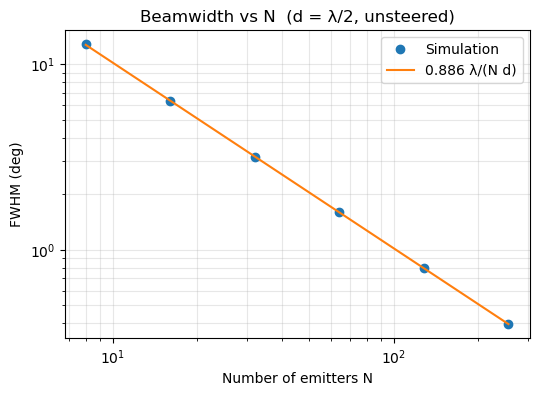

In [2]:
Ns = np.array([8, 16, 32, 64, 128, 256])
measured = [fwhm(theta, array_intensity(theta, n, d, wl, 0)) for n in Ns]
theory = np.degrees(0.886 * wl / (Ns * d))

for n, m, t in zip(Ns, measured, theory):
    print(f"N = {n:4d}:  measured {m:6.3f}°   theory {t:6.3f}°")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(Ns, measured, "o", label="Simulation")
ax.loglog(Ns, theory, "-", label="0.886 λ/(N d)")
ax.set_xlabel("Number of emitters N"); ax.set_ylabel("FWHM (deg)")
ax.set_title("Beamwidth vs N  (d = λ/2, unsteered)")
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.show()

## 3. Beamwidth against steering angle ##

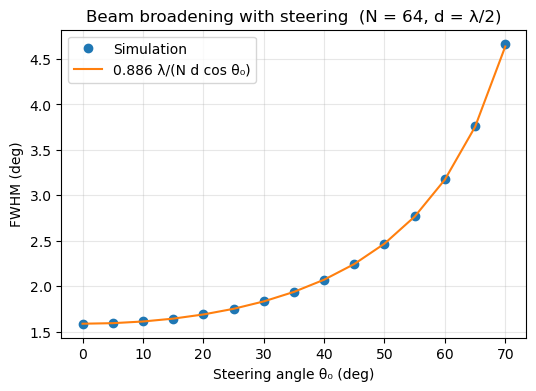

In [3]:
N = 64
steer = np.arange(0, 75, 5)
measured = []
for s in steer:
    dphi = 2 * np.pi * d / wl * np.sin(np.radians(s))
    measured.append(fwhm(theta, array_intensity(theta, N, d, wl, dphi)))
theory = np.degrees(0.886 * wl / (N * d * np.cos(np.radians(steer))))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(steer, measured, "o", label="Simulation")
ax.plot(steer, theory, "-", label="0.886 λ/(N d cos θ₀)")
ax.set_xlabel("Steering angle θ₀ (deg)"); ax.set_ylabel("FWHM (deg)")
ax.set_title(f"Beam broadening with steering  (N = {N}, d = λ/2)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 4. Sidelobe level against N (quick check) ##

In [5]:
for n in Ns:
    I = array_intensity(theta, n, d, wl, 0)
    _, vals = find_peaks(theta, I)
    print(f"N = {n:4d}:  strongest sidelobe {10*np.log10(np.sort(vals)[-2]):.2f} dB")

N =    8:  strongest sidelobe -12.80 dB
N =   16:  strongest sidelobe -13.15 dB
N =   32:  strongest sidelobe -13.23 dB
N =   64:  strongest sidelobe -13.25 dB
N =  128:  strongest sidelobe -13.26 dB
N =  256:  strongest sidelobe -13.26 dB


**Notes:** More emitters make the beam narrower but don't lower the strongest sidelobe. 

## 5. The LIDAR design question ##

How many emitters do you need for a 0.1° beam at 1550 nm with λ/2 spacing?

In [6]:
target = np.radians(0.1) # Small angle approximation
N_needed = 0.886 * wl / (d * target)
print(f"Emitters needed: {N_needed:.0f}")
print(f"Array width: {N_needed * d * 1e3:.2f} mm")
print(f"Spot size at 100 m: {100 * target * 100:.0f} cm")

Emitters needed: 1015
Array width: 0.79 mm
Spot size at 100 m: 17 cm


**Notes:** Spot size of 17cm is fine enough to resolve a pedestrian at 100m. But it needs about 1,000 independently controlled phase shifters, which is why power and control electronics are a major challenge for real LIDAR chips

**Questions:**
    
1. What does the slope of the log-log plot tell you, and why does it make physical sense? (Use the pairing argument.)
2. Why does the beam broaden with steering angle, and by how much at 60°?
3. Why doesn’t adding emitters lower the strongest sidelobe?
4. What’s the engineering cost of a 0.1° beam, and what does it mean for a real LIDAR?